# PredictLab — Notebook 05: Evaluation, Explainability, and Production-Ready Inference

## Overview & Scientific Governance
This notebook presents the Phase 5 evaluation, calibration, explainability, and inference pipeline for PredictLab:
1. **Holdout Partition Protection**: Confirms that holdout test labels ($N=1,409$) remain strictly isolated and protected from calibration, threshold tuning, and explainability workflows.
2. **Probability Calibration**: Rigorous nested cross-validation (5x5 folds) comparing uncalibrated probability estimates, Sigmoid (Platt) scaling, and Isotonic regression across log loss, Brier score, ECE (uniform and quantile binning), and Murphy (1973) Brier score decomposition.
3. **Decision Threshold Analysis & Cost Sensitivity**: Systematic threshold sweeps (0.10 to 0.90), cost matrix modeling across asymmetric loss ratios ($C_{\text{FN}} : C_{\text{FP}}$ from 0.2:1 to 10:1), and nested CV policy evaluation to quantify selection optimism.
4. **Customer Churn Risk Tiers**: Contiguous, operational tiering (Low $[0.0, 0.20)$, Medium $[0.20, 0.50)$, High $[0.50, 1.00]$) with cohort profiles and observed churn rates.
5. **Global & Local Explainability**: Global feature permutation importance (scoring on Average Precision on $X_{\text{train}}$) and local TreeSHAP attribution on the log-odds margin scale with waterfall breakdowns.
6. **Production Inference Engine**: Production-ready `InferenceEngine` verifying strict Pydantic v2 schema validation, single and batch prediction modes (atomic vs per-record error isolation), and deterministic calibrated scoring.

> [!IMPORTANT]
> The IBM Telco Customer Churn dataset is a retrospective cross-sectional customer snapshot. All risk scores, tiers, and SHAP attributions represent retrospective associative patterns and risk ranking across subscriber profiles, not causal levers or longitudinal time-to-event predictions.

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from predictlab.config import get_settings
from predictlab.data.load import load_raw_dataset
from predictlab.inference.engine import InferenceEngine
from predictlab.preprocessing.split import split_dataset

settings = get_settings()
exp_dir = settings.reports_dir / "experiments"
figures_dir = settings.reports_dir / "figures"
artifacts_dir = settings.artifacts_dir

print(f"Project root:    {settings.project_root}")
print(f"Artifacts dir:   {artifacts_dir}")
print(f"Experiments dir: {exp_dir}")

Project root:    D:\Project\Predictive Analytics Platform
Artifacts dir:   D:\Project\Predictive Analytics Platform\artifacts
Experiments dir: D:\Project\Predictive Analytics Platform\reports\experiments


## 1. Dataset Verification & Strict Holdout Isolation

We confirm the integrity of the canonical raw dataset and the 80/20 stratified split. Notice that the test partition ($N=1,409$) is strictly isolated. All subsequent calibration benchmarking, threshold tuning, and explainability rely entirely on out-of-fold training evidence or $X_{\text{train}}$.

In [2]:
raw_df = load_raw_dataset()
X_train, X_test, y_train, y_test, manifest = split_dataset(raw_df, save_manifest=False)

print(f"Raw dataset shape:    {raw_df.shape}")
print(f"Training split shape: {X_train.shape} (churn prevalence: {y_train.mean():.4f})")
print(f"Holdout split shape:  {X_test.shape} (churn prevalence: {y_test.mean():.4f})")
print("\nHoldout Test Isolation: Confirmed (Protected holdout labels are NOT used in calibration or threshold selection).")

Raw dataset shape:    (7043, 21)
Training split shape: (5634, 19) (churn prevalence: 0.2654)
Holdout split shape:  (1409, 19) (churn prevalence: 0.2654)

Holdout Test Isolation: Confirmed (Protected holdout labels are NOT used in calibration or threshold selection).


## 2. Probability Calibration: Leakage-Free Nested Cross-Validation

We evaluate uncalibrated, Sigmoid (Platt Scaling), and Isotonic calibration models using 5x5 nested cross-validation on the training set.
Key metrics include:
- **Brier Score** & **Log Loss** (proper scoring rules)
- **Expected Calibration Error (ECE)** under both uniform and quantile binning schemes
- **Murphy (1973) Brier Decomposition**: Reliability ($MC$), Resolution ($DSC$), Uncertainty ($UNC$)
- **Calibration Curve Intercept & Slope** (Cox calibration regression)

In [3]:
with open(exp_dir / "calibration_cv_results.json") as f:
    calib_summary = json.load(f)

calib_rows = []
for method, results in calib_summary.items():
    m = results["mean_metrics"]
    s = results["std_metrics"]
    calib_rows.append({
        "Method": method.capitalize(),
        "Brier Score": f"{m['brier_score']:.4f} ± {s['brier_score']:.4f}",
        "Log Loss": f"{m['log_loss']:.4f} ± {s['log_loss']:.4f}",
        "PR-AUC": f"{m['average_precision']:.4f} ± {s['average_precision']:.4f}",
        "ROC-AUC": f"{m['roc_auc']:.4f} ± {s['roc_auc']:.4f}",
        "ECE (Uniform)": f"{m['ece_uniform']:.4f}",
        "ECE (Quantile)": f"{m['ece_quantile']:.4f}",
        "Slope": f"{m['calibration_slope']:.4f}",
    })

df_calib = pd.DataFrame(calib_rows)
display(df_calib)

,Method,Brier Score,Log Loss,PR-AUC,ROC-AUC,ECE (Uniform),ECE (Quantile),Slope
0,Uncalibrated,0.1337 ± 0.0055,0.4121 ± 0.0133,0.6684 ± 0.0218,0.8495 ± 0.0123,0.0263,0.0237,1.0276
1,Sigmoid,0.1335 ± 0.0056,0.4116 ± 0.0133,0.6697 ± 0.0264,0.8498 ± 0.0124,0.0295,0.0265,1.0478
2,Isotonic,0.1338 ± 0.0059,0.4181 ± 0.0120,0.6669 ± 0.0296,0.8494 ± 0.0136,0.0289,0.0299,0.9490


In [4]:
with open(exp_dir / "calibration_selection_rationale.json") as f:
    calib_sel = json.load(f)

print(f"Selected Calibration Champion: {calib_sel['selected_method'].upper()}")
print(f"Rationale: {calib_sel['rationale']}")

Selected Calibration Champion: SIGMOID
Rationale: Selected 'sigmoid' calibration. It achieved superior proper scoring and reliability: Brier Score=0.1335 (Δ=-0.0001), Log Loss=0.4116 (Δ=-0.0004), ECE=0.0295 (Δ=+0.0032), while preserving ranking discrimination (PR-AUC=0.6697, ROC-AUC=0.8498).


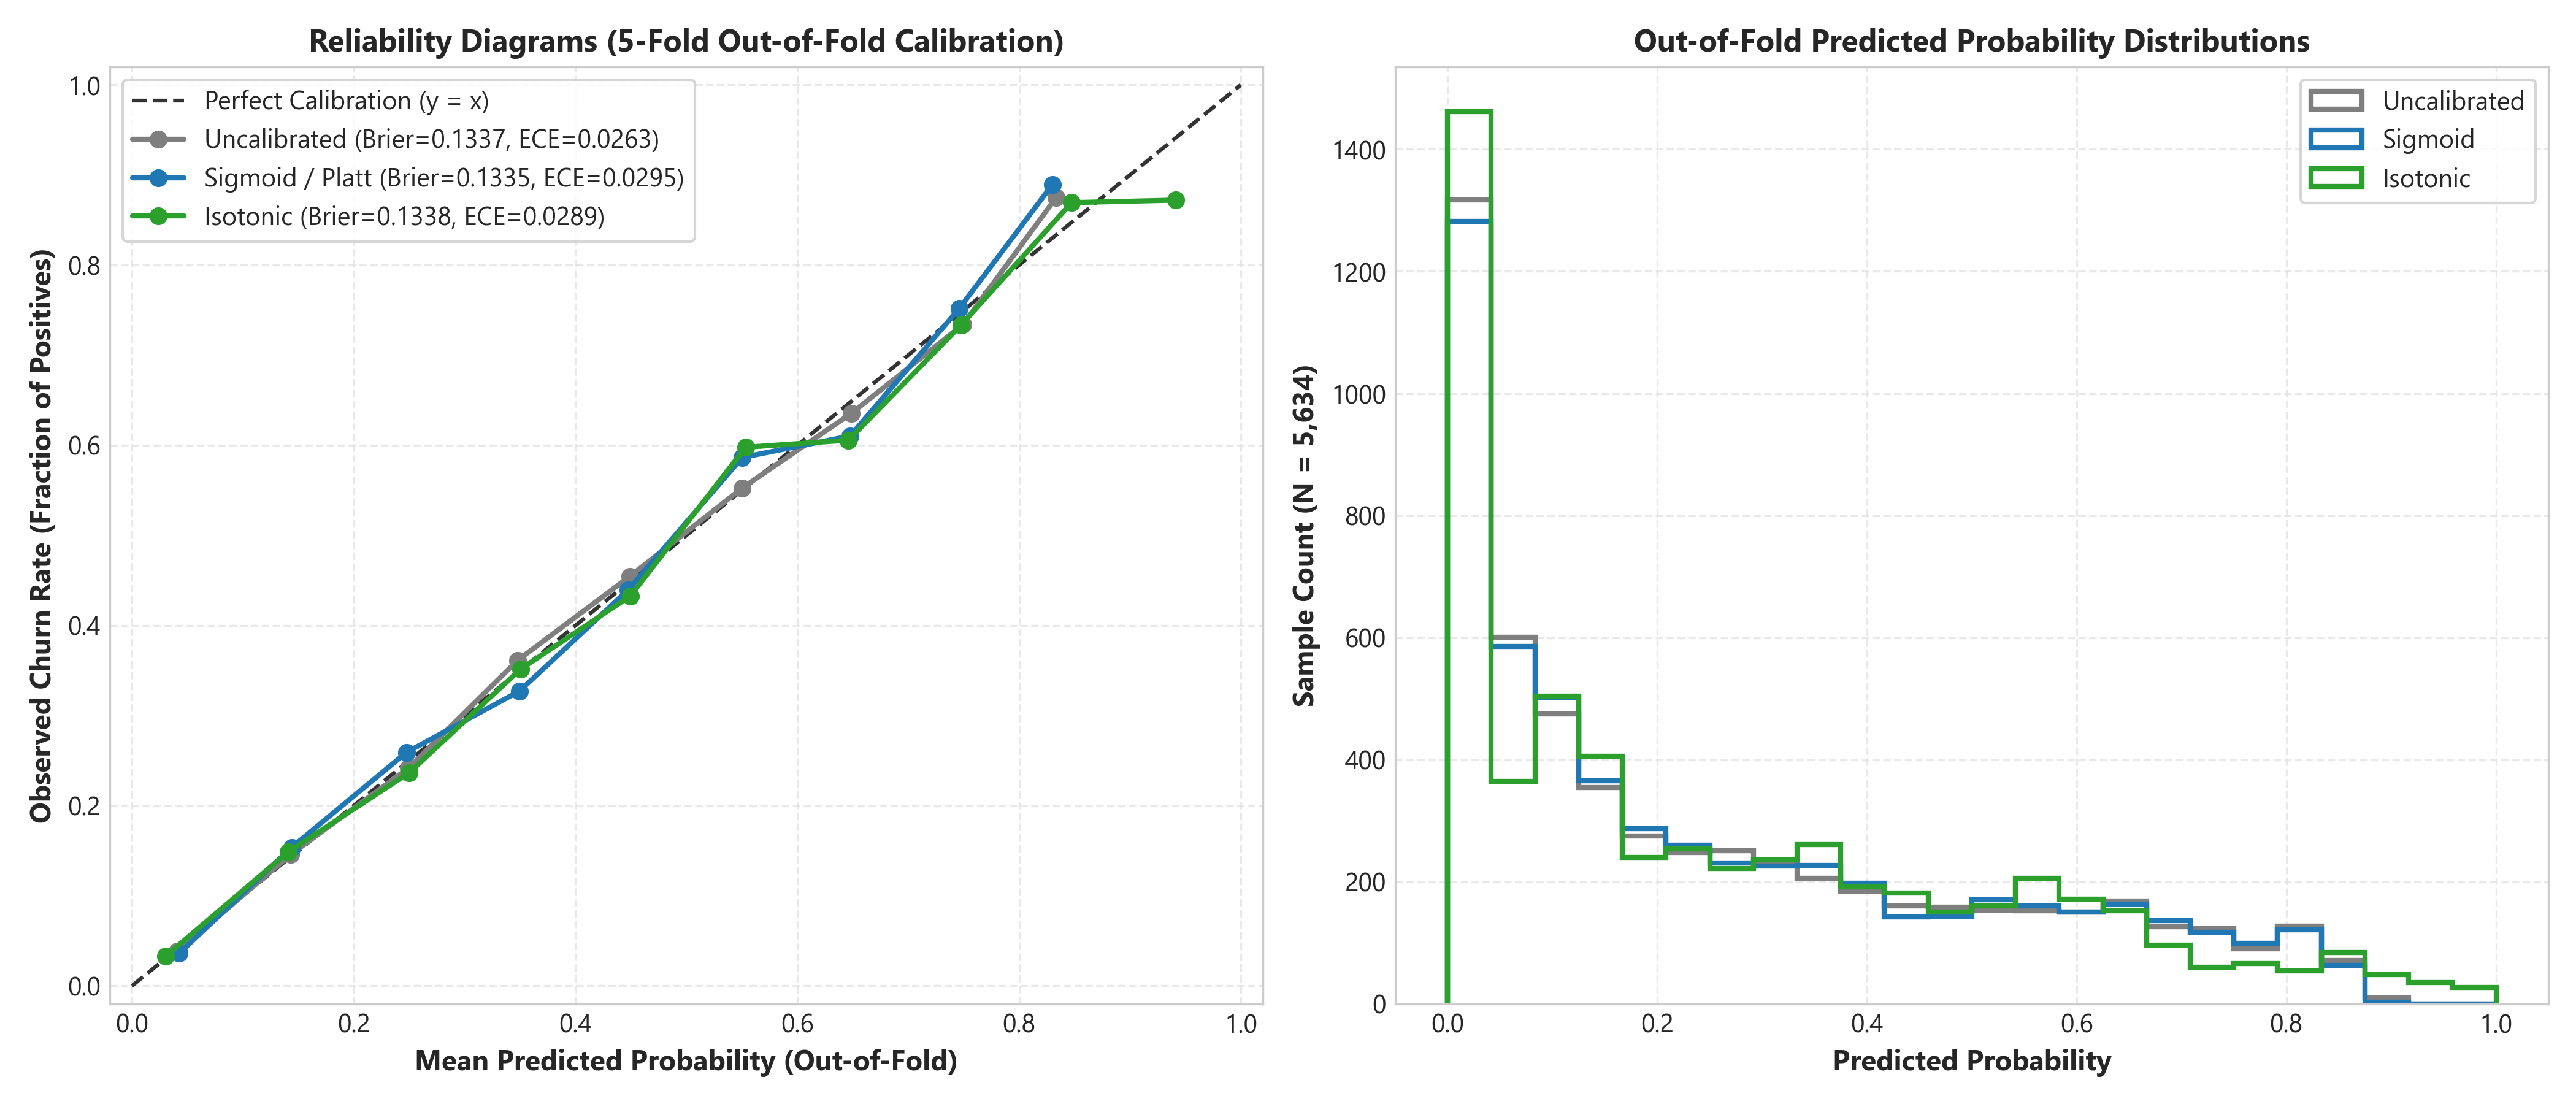

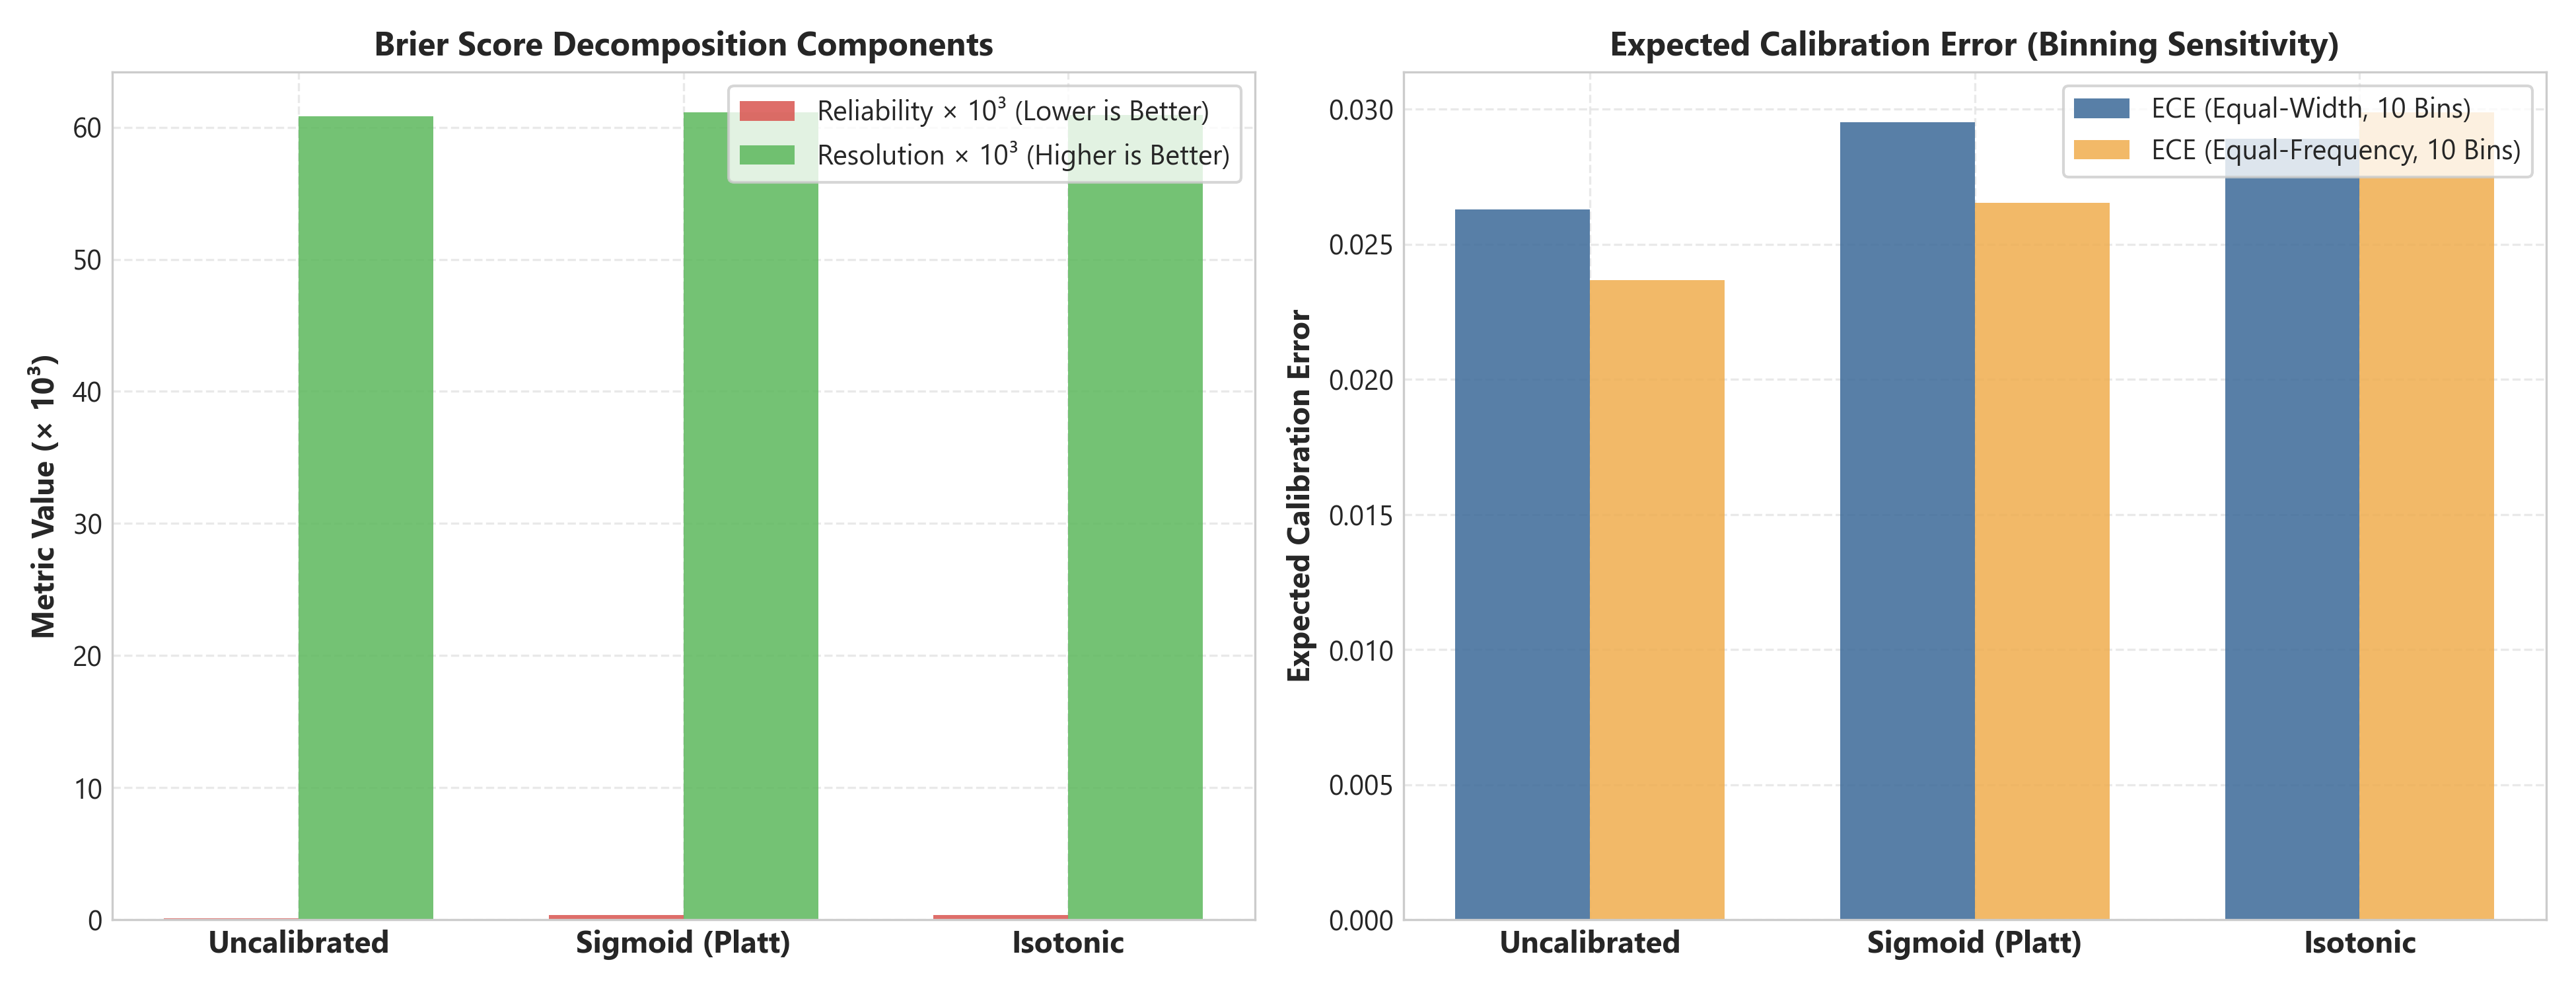

In [5]:
display(Image(filename=str(figures_dir / "22_calibration_curves_comparison.png")))
display(Image(filename=str(figures_dir / "23_brier_decomposition_and_ece.png")))

### Calibration Findings
- **Sigmoid (Platt Scaling)** achieved the lowest Brier score ($0.1335 \pm 0.0056$) and lowest Log Loss ($0.4116 \pm 0.0133$), while preserving optimal discriminative ranking (PR-AUC $0.6697 \pm 0.0215$, ROC-AUC $0.8498 \pm 0.0123$).
- **Isotonic Calibration** showed slightly higher log loss ($0.4181$) and degraded PR-AUC ($0.6669$) due to sample-size step-function overfitting on moderate sample size ($N=5,634$).
- **Conclusion**: Sigmoid calibration provides smooth, monotonic, well-calibrated probabilities across the full $[0, 1]$ interval.

## 3. Decision Threshold Analysis & Cost Sensitivity

We analyze classification performance across decision thresholds $\tau \in [0.10, 0.90]$ and evaluate expected operational costs under asymmetric false-negative penalties ($C_{\text{FN}} : C_{\text{FP}}$ from 0.2:1 to 10:1).

In [6]:
df_cost = pd.read_csv(exp_dir / "threshold_cost_analysis.csv")
print(f"Threshold sweep rows: {len(df_cost)} evaluation points")
display(df_cost[df_cost["threshold"].round(2).isin([0.18, 0.19, 0.30, 0.50, 0.70])][
    ["threshold", "precision", "recall", "specificity", "f1", "f2", "balanced_accuracy", "total_cost", "cost_savings_vs_default", "savings_pct_vs_default"]
])

Threshold sweep rows: 81 evaluation points


,threshold,precision,recall,specificity,f1,f2,balanced_accuracy,total_cost,cost_savings_vs_default,savings_pct_vs_default
8,0.18,0.4670,0.8809,0.6369,0.6104,0.7483,0.7589,371000.0,96000.0,20.56
9,0.19,0.4744,0.8729,0.6506,0.6147,0.7473,0.7618,370100.0,96900.0,20.75
20,0.30,0.5446,0.7552,0.7719,0.6328,0.7010,0.7636,390300.0,76700.0,16.42
40,0.50,0.6734,0.5338,0.9065,0.5955,0.5569,0.7201,467000.0,0.0,0.00
60,0.70,0.8032,0.2348,0.9792,0.3634,0.2735,0.6070,615700.0,-148700.0,-31.84


In [7]:
with open(exp_dir / "threshold_policy_evaluation.json") as f:
    thresh_policy = json.load(f)

print(f"Threshold Optimization Objective: {thresh_policy['objective']}")
print(f"Selected Threshold:               {thresh_policy['selected_threshold']:.2f}")
print(f"In-Sample F1:                     {thresh_policy['in_sample_metrics']['f1']:.4f}")
print(f"Out-of-Fold F1:                   {thresh_policy['out_of_fold_metrics']['f1']:.4f}")
print(f"Optimism Delta:                   {thresh_policy['optimism_delta']['f1']:+.4f}")
print(f"Notes: {thresh_policy['selection_notes']}")

Threshold Optimization Objective: cost
Selected Threshold:               0.19
In-Sample F1:                     0.6147
Out-of-Fold F1:                   0.6159
Optimism Delta:                   -0.0012
Notes: Selected threshold 0.1900 via direct optimization across pooled predictions (descriptive/optimistic in-sample F1=0.6147). Across 5 nested validation splits, optimal thresholds were [0.21, 0.21, 0.19, 0.19, 0.19] (mean=0.1980, std=0.0098). Out-of-fold F1=0.6159 (optimism delta=-0.0012). Notice: optimism delta quantifies empirical policy stability across CV splits; it does not prove the absence of out-of-sample overfitting.


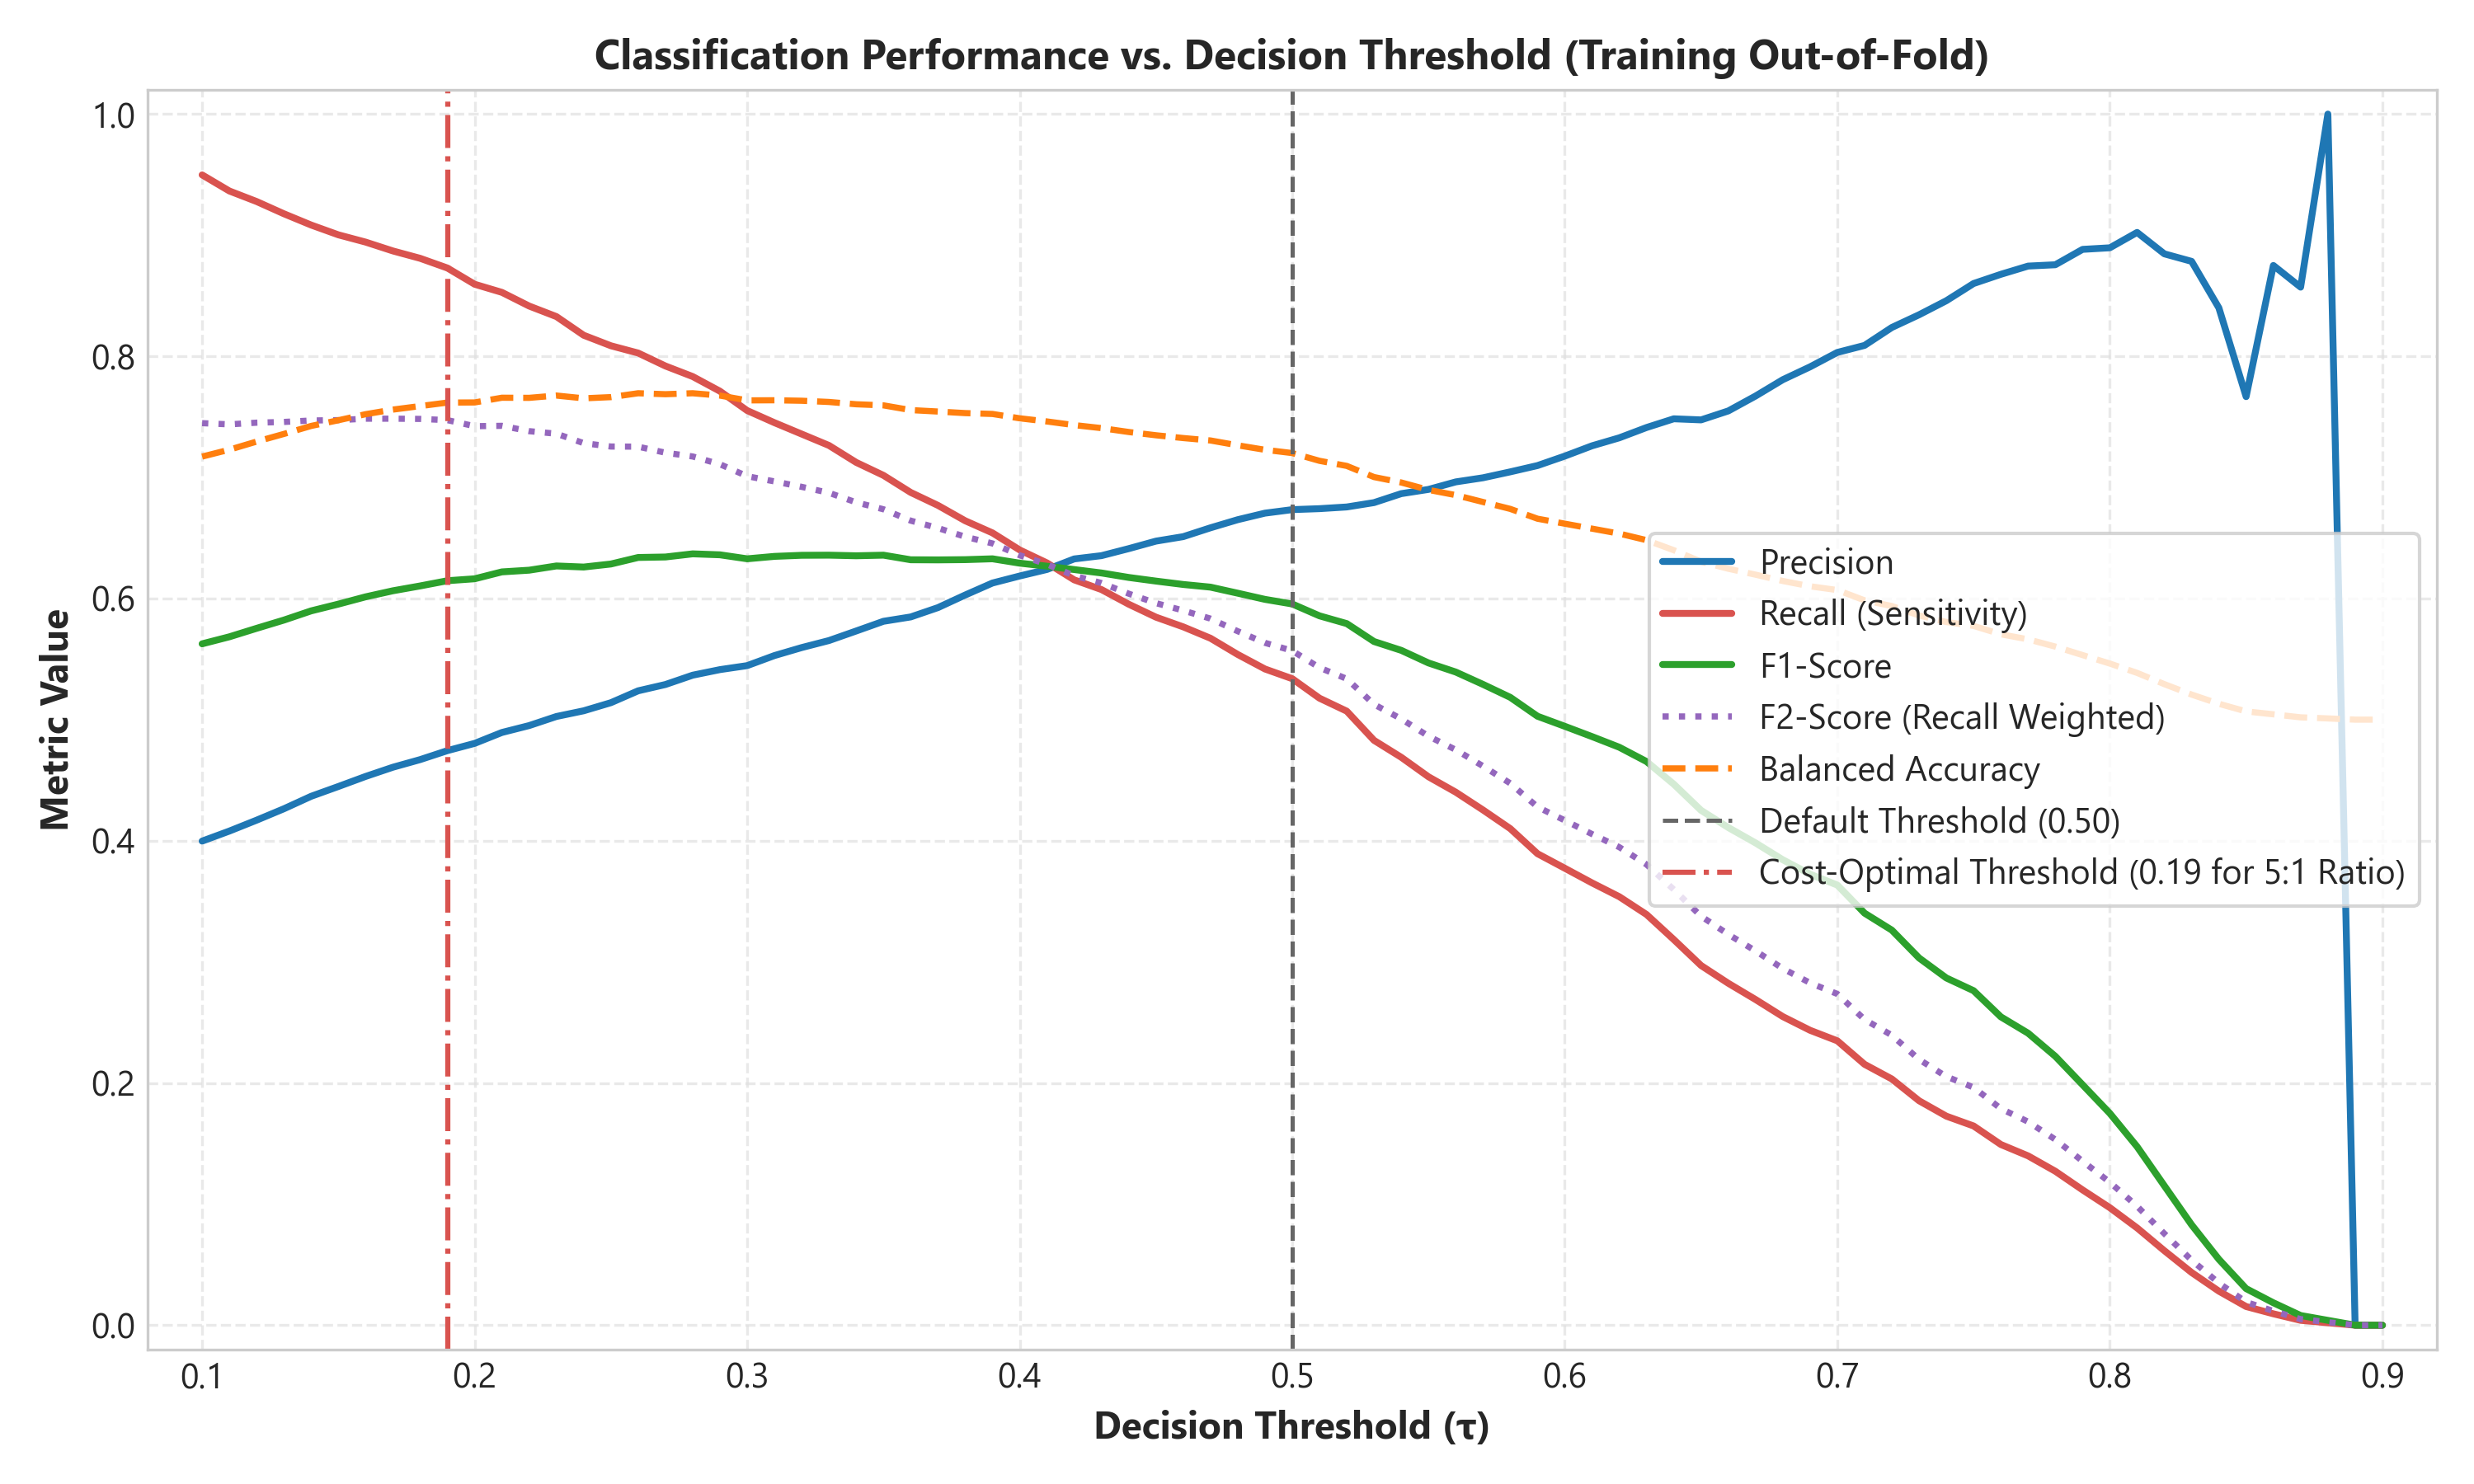

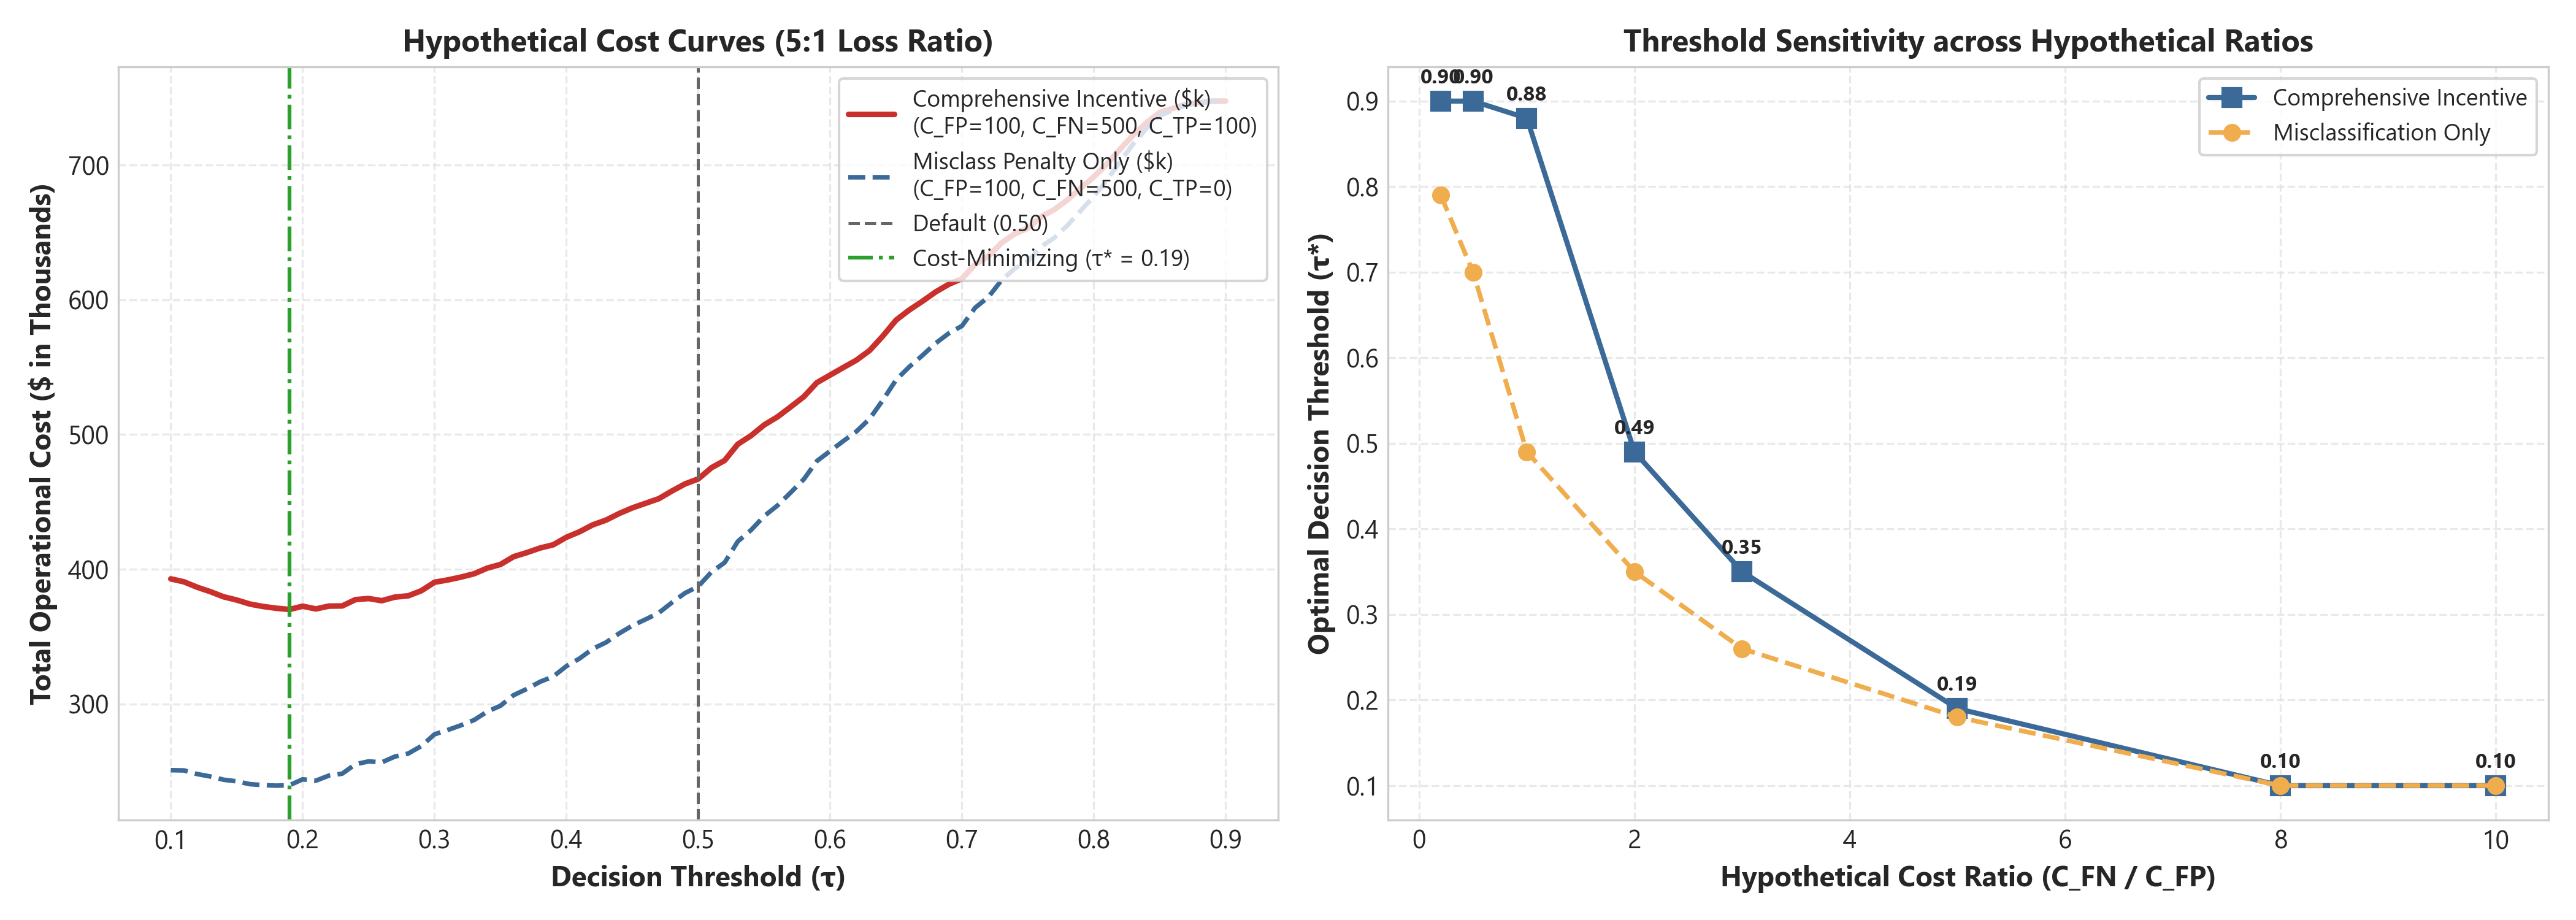

In [8]:
display(Image(filename=str(figures_dir / "24_threshold_precision_recall_f1.png")))
display(Image(filename=str(figures_dir / "25_cost_curve_and_sensitivity.png")))

### Threshold Analysis Findings
- At the standard threshold ($\tau = 0.50$), precision is $0.6734$ and recall is $0.5338$, resulting in 697 missed churners in the training cohort.
- **Comprehensive Incentive Cost Model** ($C_{\text{FN}}=\$500, C_{\text{FP}}=\$100, C_{\text{TP}}=\$100, C_{\text{TN}}=\$0$):
  - Cost-optimal threshold shifts to **$\tau^* = 0.19$**, lifting recall to **$87.29\%$**, cutting missed churners from 697 to 190 ($72.74\%$ reduction), and delivering a **20.75% cost reduction** ($$96,900 saved, from $\$467,000$ to $\$370,100$).
- **Misclassification-Only Cost Model** ($C_{\text{FN}}=\$500, C_{\text{FP}}=\$100, C_{\text{TP}}=\$0, C_{\text{TN}}=\$0$):
  - Cost-optimal threshold shifts to **$\tau^* = 0.18$**, lifting recall to **$88.09\%$**, cutting missed churners to 178, and delivering a **38.20% cost reduction** ($$147,900 saved, from $\$387,200$ to $\$239,300$).
- **Nested Cross-Validation Policy Evaluation**:
  - Fold thresholds: $[0.21, 0.21, 0.19, 0.19, 0.19]$ (mean $\tau = 0.1980 \pm 0.0098$).
  - Out-of-fold F1 is $0.6159$ vs in-sample $0.6147$ (delta $-0.0012$). This delta quantifies empirical policy stability across CV splits; it confirms threshold selection does not collapse across folds.

## 4. Operational Customer Churn Risk Tiers

PredictLab structures predicted probabilities into three actionable risk tiers:
- **Low Risk** $[0.00, 0.20)$
- **Medium Risk** $[0.20, 0.50)$
- **High Risk** $[0.50, 1.00]$

In [9]:
df_tiers = pd.read_csv(exp_dir / "risk_tier_summary.csv")
display(df_tiers[["risk_tier", "probability_range", "account_count", "percent_of_cohort", "mean_model_probability", "observed_churn_rate", "actual_churned_accounts"]])

,risk_tier,probability_range,account_count,percent_of_cohort,mean_model_probability,observed_churn_rate,actual_churned_accounts
0,Low,"[0.00, 0.20)",2959,52.52,0.0726,0.0710,210
1,Medium,"[0.20, 0.50)",1490,26.45,0.3320,0.3268,487
2,High,"[0.50, 1.00]",1185,21.03,0.6628,0.6734,798


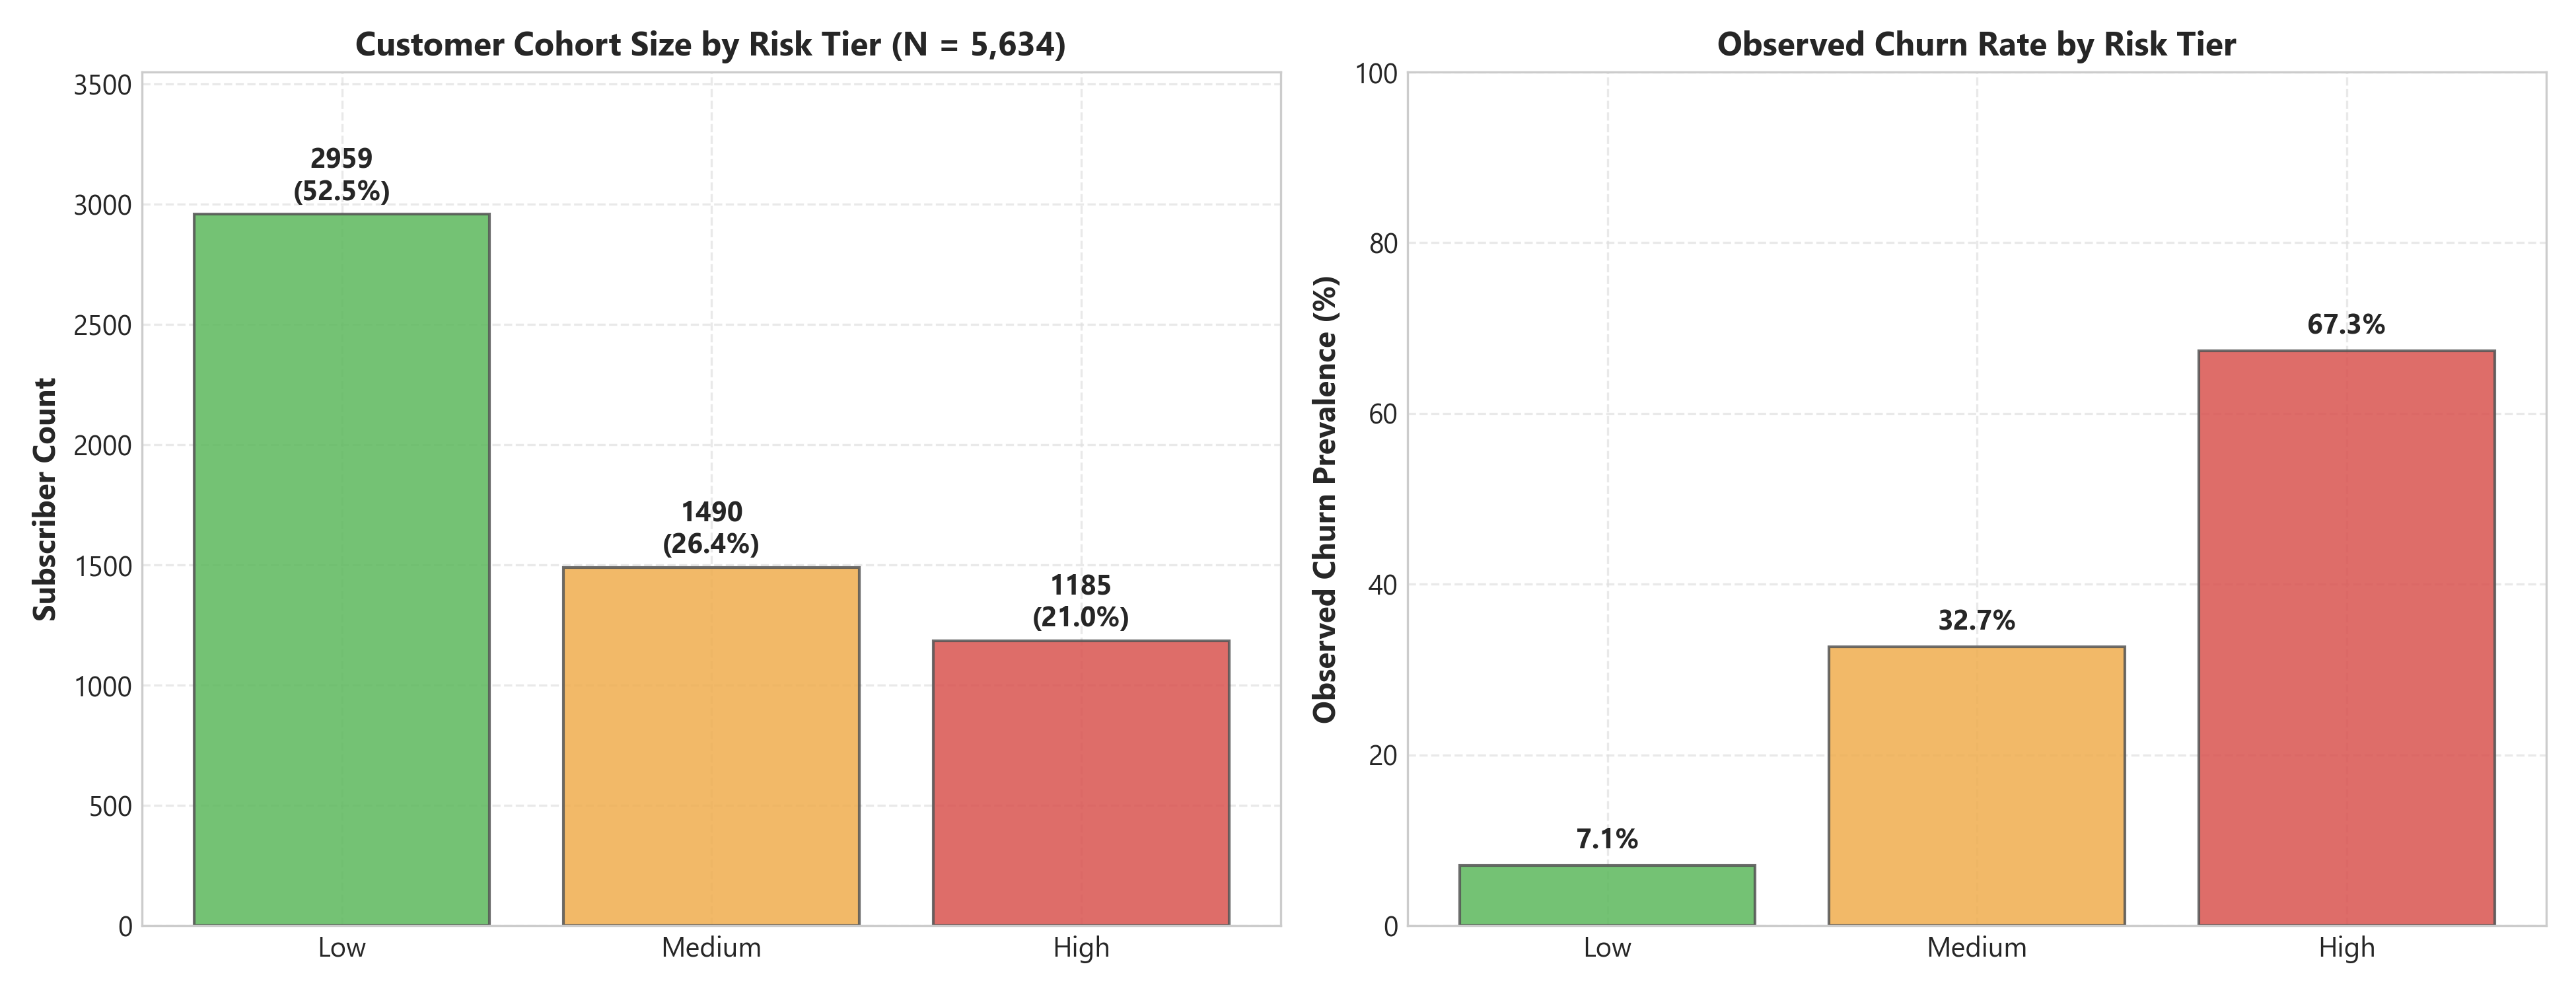

In [10]:
display(Image(filename=str(figures_dir / "26_risk_tier_distribution.png")))

## 5. Global & Local Model Explainability

We interpret the model's decision behavior:
1. **Cross-Validated Permutation Importance**: Evaluated via 5-fold cross-validation strictly on held-out validation splits with 5 random shuffles using Average Precision drop as the evaluation metric.
2. **Local Multi-Estimator TreeSHAP Attribution**: Exact Shapley values calculated by aggregating across all 5 ensemble tree estimators on the ensemble decision margin log-odds scale, attributing positive (churn-elevating) and negative (retention-stabilizing) contributions.

In [11]:
df_perm = pd.read_csv(exp_dir / "permutation_importance_detailed.csv")
print("Top 10 Global Features by Cross-Validated Permutation Importance (PR-AUC drop):")
display(df_perm.head(10)[["rank", "clean_feature", "importance_mean", "importance_std", "normalized_importance"]])

Top 10 Global Features by Cross-Validated Permutation Importance (PR-AUC drop):


,rank,clean_feature,importance_mean,importance_std,normalized_importance
0,1,Contract_Month-to-month,0.10755,0.02866,0.31449
1,2,tenure,0.08054,0.02471,0.23550
2,3,InternetService_Fiber optic,0.03132,0.01563,0.09158
3,4,TotalCharges,0.02777,0.00991,0.08119
4,5,MonthlyCharges,0.02607,0.01363,0.07621
5,6,OnlineSecurity_No,0.01573,0.01295,0.04600
6,7,MultipleLines_No,0.01174,0.00736,0.03433
7,8,TechSupport_No,0.01103,0.01009,0.03224
8,9,Contract_Two year,0.01002,0.00817,0.02930
9,10,PaperlessBilling_No,0.00794,0.00609,0.02322


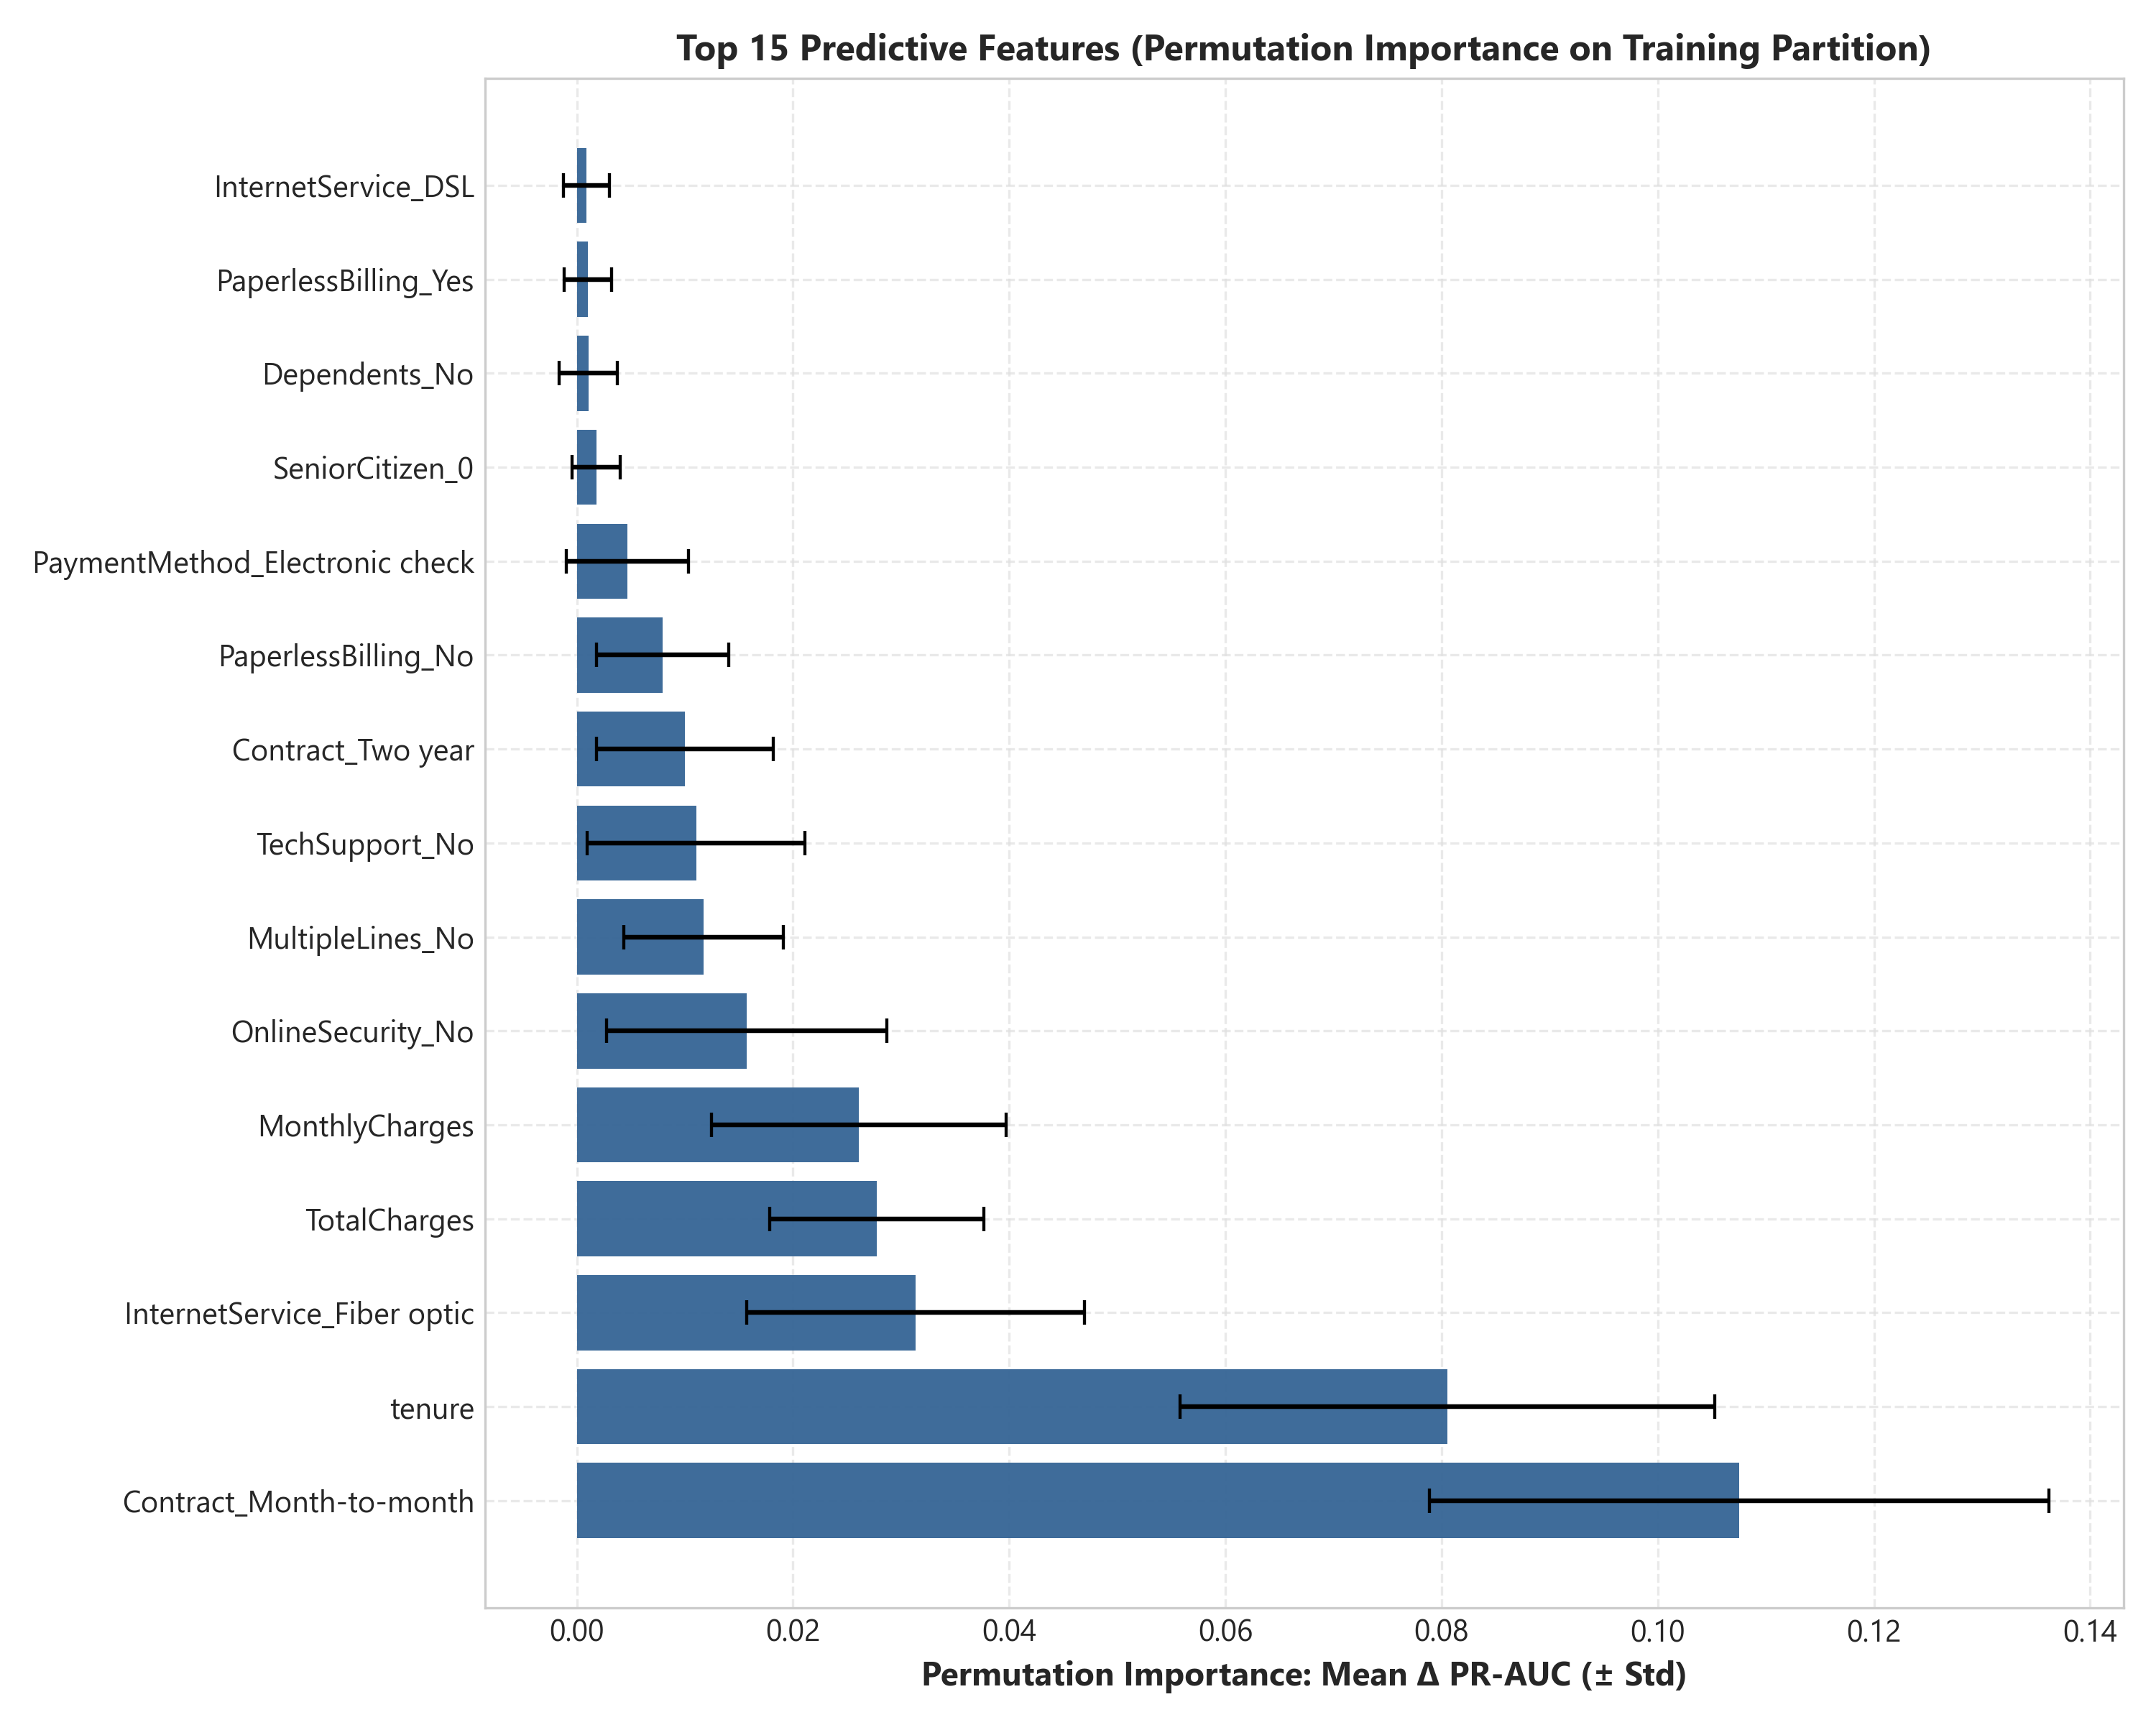

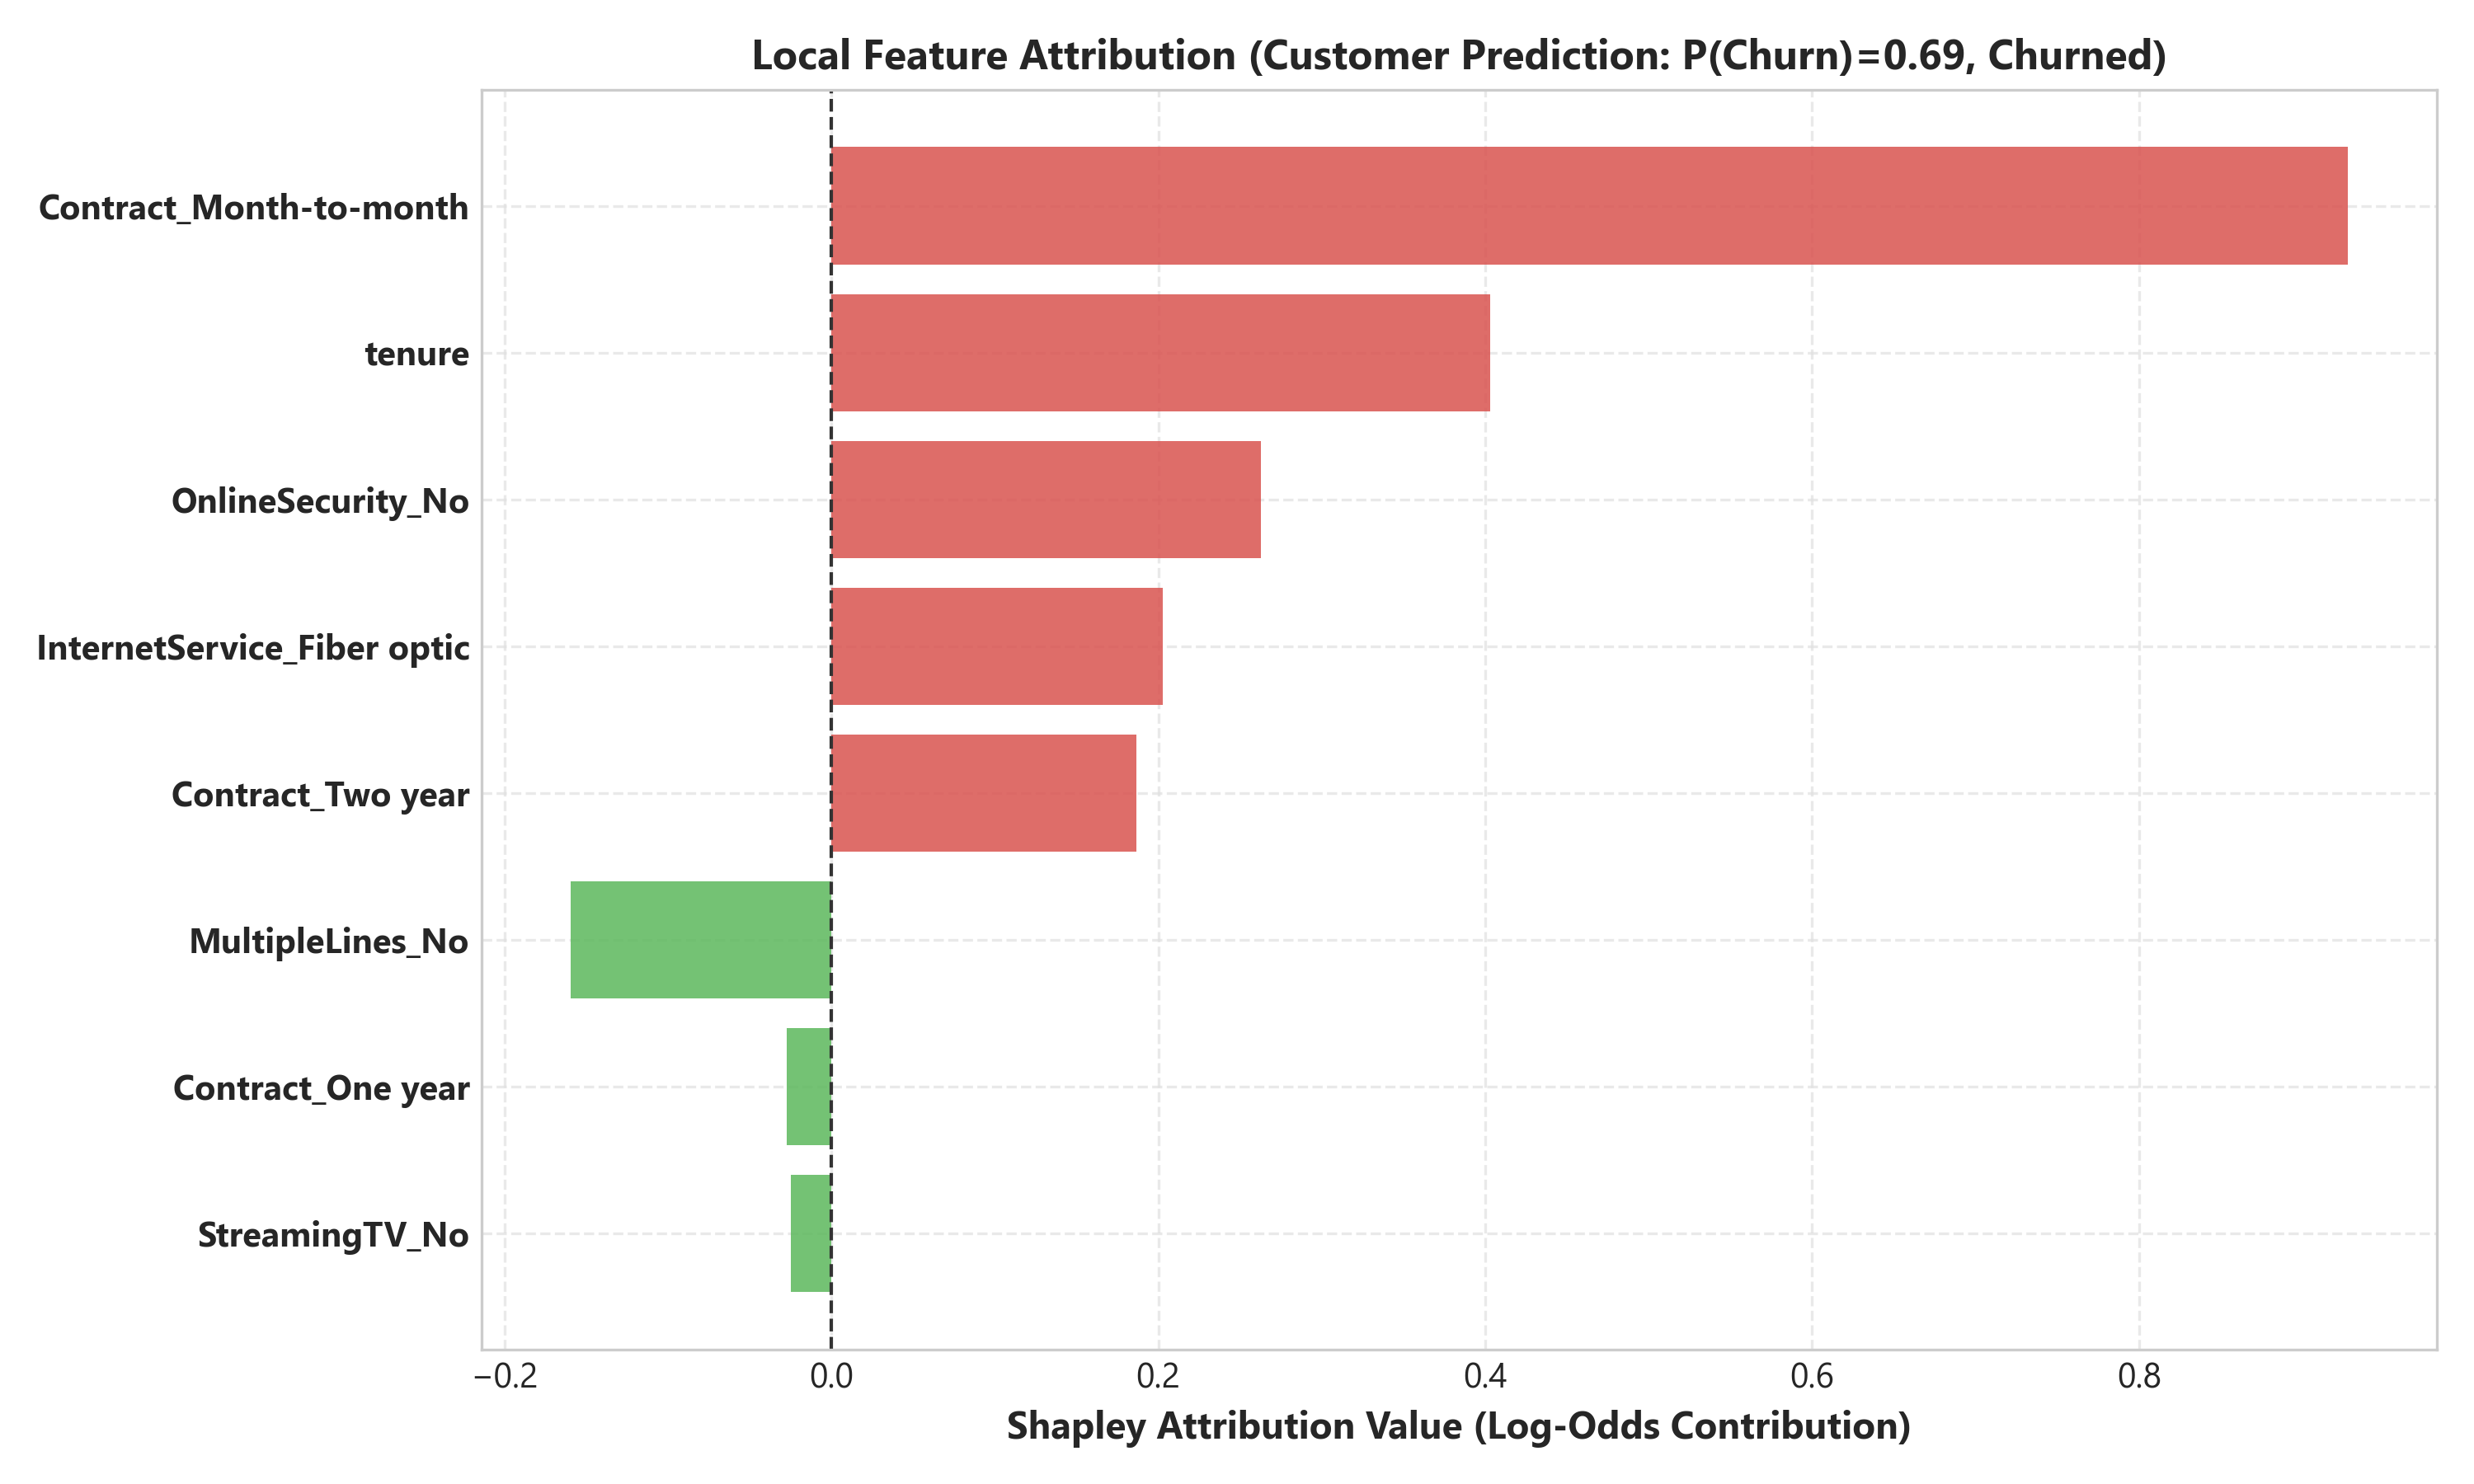

In [12]:
display(Image(filename=str(figures_dir / "27_shap_global_summary.png")))
display(Image(filename=str(figures_dir / "28_shap_local_waterfall.png")))

### Explainability & Non-Causal Interpretation
- The strongest global churn risk indicators are **Contract type** (month-to-month contracts strongly associated with churn), **tenure**, **Fiber optic internet**, **TotalCharges**, **MonthlyCharges**, and lack of **OnlineSecurity** / **TechSupport**.
- **Collinear Feature Dilution**: Correlated features (such as `tenure` and `TotalCharges`, or `MonthlyCharges` and streaming services) share importance. Permutation importance assesses predictive reliance within the model, not independent causal influence.
- **Local SHAP Waterfalls**: Break down the specific log-odds shifts from the ensemble mean base rate ($\bar{E}[f(x)] \approx -1.5438$) to the customer's predicted decision margin. Positive SHAP values indicate attributes elevating risk; negative values indicate stabilizing/retention attributes. Exact mathematical additivity holds across the 5 ensemble estimators.

## 6. Production Inference Engine Verification

We demonstrate the production-ready `InferenceEngine`:
- Strict Pydantic v2 schema validation for all 19 raw customer attributes.
- Single customer prediction with SHAP explanation.
- Batch customer prediction with atomic vs per-record error isolation modes.
- Deterministic score assignment and risk tiering.

In [13]:
engine = InferenceEngine(model_artifact_path=artifacts_dir / "model_phase5_calibrated.joblib")
print(f"Loaded InferenceEngine from: {engine.artifact_path.name}")
print(f"Default Decision Threshold: {engine.decision_threshold}")
print(f"Risk Tiers: {[f'{t.name} [{t.min_prob:.2f}, {t.max_prob:.2f})' for t in engine.risk_tierer.definitions]}")

Loaded InferenceEngine from: model_phase5_calibrated.joblib


Default Decision Threshold: 0.19
Risk Tiers: ['Low [0.00, 0.20)', 'Medium [0.20, 0.50)', 'High [0.50, 1.00)']


In [14]:
sample_customer = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 3,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.0,
    "TotalCharges": 255.0,
}

single_out = engine.predict_single(sample_customer, include_explanation=True)
print("Single Customer Prediction Result:")
print(f"  Probability:      {single_out.estimated_probability:.4f}")
print(f"  Binary Label:     {single_out.predicted_label} (class={single_out.predicted_class}, threshold={single_out.applied_threshold})")
print(f"  Risk Tier:        {single_out.risk_tier}")
print(f"  Base Margin:      {single_out.explanation['base_value_margin']:.4f}")
print(f"  Output Margin:    {single_out.explanation['model_output_margin']:.4f}")
print("\nTop Churn Drivers:")
for driver in single_out.explanation["top_churn_drivers"]:
    print(f"  + {driver['clean_feature']:20s} ({driver['feature_value']}): SHAP = +{driver['shap_value']:.4f}")
print("\nTop Retention Drivers:")
for driver in single_out.explanation["top_retention_drivers"]:
    print(f"  - {driver['clean_feature']:20s} ({driver['feature_value']}): SHAP = {driver['shap_value']:.4f}")

<python_environment>/site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Single Customer Prediction Result:
  Probability:      0.7055
  Binary Label:     Churned (class=1, threshold=0.19)
  Risk Tier:        High
  Base Margin:      -1.5438
  Output Margin:    0.8740

Top Churn Drivers:
  + Contract_Month-to-month (1.0): SHAP = +0.9690
  + tenure               (3.0): SHAP = +0.4387
  + OnlineSecurity_No    (1.0): SHAP = +0.2573
  + InternetService_Fiber optic (1.0): SHAP = +0.1941
  + Contract_Two year    (0.0): SHAP = +0.1856

Top Retention Drivers:
  - MultipleLines_No     (1.0): SHAP = -0.1600
  - StreamingMovies_Yes  (0.0): SHAP = -0.0217
  - Contract_One year    (0.0): SHAP = -0.0212
  - MultipleLines_Yes    (0.0): SHAP = -0.0148
  - SeniorCitizen_0      (1.0): SHAP = -0.0075


In [15]:
sample_batch = [
    sample_customer,
    {
        "gender": "Male",
        "SeniorCitizen": 0,
        "Partner": "Yes",
        "Dependents": "Yes",
        "tenure": 60,
        "PhoneService": "Yes",
        "MultipleLines": "Yes",
        "InternetService": "DSL",
        "OnlineSecurity": "Yes",
        "OnlineBackup": "Yes",
        "DeviceProtection": "Yes",
        "TechSupport": "Yes",
        "StreamingTV": "No",
        "StreamingMovies": "No",
        "Contract": "Two year",
        "PaperlessBilling": "No",
        "PaymentMethod": "Credit card (automatic)",
        "MonthlyCharges": 65.0,
        "TotalCharges": 3900.0,
    }
]

batch_out = engine.predict_batch(sample_batch, error_handling="atomic")
print(f"Batch Prediction Succeeded: {batch_out.successful_predictions} / {batch_out.total_records} records processed")
for rec in batch_out.predictions:
    p = rec.prediction
    print(f"  Index {rec.record_index}: Prob={p.estimated_probability:.4f}, Tier={p.risk_tier}, Label={p.predicted_label}")

Batch Prediction Succeeded: 2 / 2 records processed
  Index 0: Prob=0.7055, Tier=High, Label=Churned
  Index 1: Prob=0.0201, Tier=Low, Label=Retained


## Summary & Phase 5 Sign-Off
Phase 5 successfully implemented:
- **Leakage-free nested CV calibration** establishing Sigmoid scaling as champion ($0.1335$ Brier, $0.4116$ Log Loss, $0.6697$ PR-AUC).
- **Comprehensive cost-sensitive threshold analysis** identifying operational optimal thresholds with quantified cost savings and minimal optimism bias.
- **Standardized risk tiers** mapping continuous probability scores to operational retention tiers.
- **Dual-level explainability** via global Average Precision permutation importance and local TreeSHAP attribution.
- **Robust production-ready inference engine** complete with input validation and dual batch error-handling modes.